<a href="https://colab.research.google.com/github/vanitripathi24/UCS420/blob/main/ucs420_assgn7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
ROLL_NO = 1024160073
NAME = "Vani Tripathi"

In [8]:
ROLL_NO = 1024160073

import random, hashlib, string
import pandas as pd
import nltk
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

for pkg in ["punkt", "punkt_tab", "stopwords"]:
    nltk.download(pkg, quiet=True)

def generate_dataset(roll_no):
    rng = random.Random(int(roll_no))
    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

STOP = set(stopwords.words("english"))

def is_punct(token):
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

# Generate dataset & print fingerprint
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Fingerprint: {FINGERPRINT} | Focus Tickets: {FOCUS}\n")

# Q1: Run process_ticket() on every ticket
rows = []
processed_results = {}

for _, row in df.iterrows():
    tid = row["Ticket_ID"]
    text = row["Ticket_Text"]
    res = process_ticket(text)
    processed_results[tid] = res

    rows.append({
        "Ticket_ID": tid,
        "Sentences": len(res["sentences"]),
        "Tokens": len(res["tokens"]),
        "Punctuation": len(res["punct"]),
        "Stopwords": len(res["stops"]),
        "Unique_Tokens": len(set(res["tokens"])),
        "Final_Tokens": len(res["final"])
    })

summary_df = pd.DataFrame(rows)
total_row = pd.DataFrame([{
    "Ticket_ID": "TOTAL",
    "Sentences": summary_df["Sentences"].sum(),
    "Tokens": summary_df["Tokens"].sum(),
    "Punctuation": summary_df["Punctuation"].sum(),
    "Stopwords": summary_df["Stopwords"].sum(),
    "Unique_Tokens": summary_df["Unique_Tokens"].sum(),
    "Final_Tokens": summary_df["Final_Tokens"].sum()
}])

summary_table = pd.concat([summary_df, total_row], ignore_index=True)
print("=== Q1: Preprocessing Summary Table ===")
print(summary_table.to_string(index=False))

# Detailed breakdown for one selected ticket
selected_id = FOCUS[0]
selected_text = df.loc[df["Ticket_ID"] == selected_id, "Ticket_Text"].values[0]
sel_res = processed_results[selected_id]

print(f"\n=== Detailed Breakdown for Selected Ticket: {selected_id} ===")
print(f"Raw Text    : {selected_text}")
print(f"Tokens      : {sel_res['tokens']}")
print(f"Punctuation : {sel_res['punct']}")
print(f"Stopwords   : {sel_res['stops']}")
print(f"Final Tokens: {sel_res['final']}")

Fingerprint: BD2C5EF8 | Focus Tickets: ['T08', 'T09']

=== Q1: Preprocessing Summary Table ===
Ticket_ID  Sentences  Tokens  Punctuation  Stopwords  Unique_Tokens  Final_Tokens
      T01          2      10            4          3              8             3
      T02          2      14            2          5             13             7
      T03          2      19            2          8             18             9
      T04          2       8            2          1              7             5
      T05          2      14            2          4             13             8
      T06          2      10            2          3              9             5
      T07          2      16            2          6             14             8
      T08          2      11            2          3             10             6
      T09          2      15            2          6             14             7
      T10          2      11            2          4             10             5
   

In [9]:
import re

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# --- Regex Patterns ---
# 1. Extraction patterns
PAT_LONG_WORDS  = r"\b[A-Za-z]{6,}\b"                          # words longer than 5 letters (>5)
PAT_NUMBERS     = r"\b\d+(?:[.,]\d+)*\b"                       # integers, decimals (95.5, 1,250), and versions (2.0.1)
PAT_CAPITALIZED = r"\b[A-Z][a-zA-Z]*\b"                        # words starting with an uppercase letter
PAT_VOWEL_START = r"\b[AEIOUaeiou][a-zA-Z]*\b"                 # words beginning with a vowel

# 2. Replacement patterns (order matters: emails before URLs so domains in emails aren't matched as URLs)
PAT_EMAIL = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
PAT_URL   = r"\b(?:https?://|www\.)[^\s,;]+"
PAT_PHONE = r"(?:\+\d{1,3}[\s-]?)?(?:\d{5}[\s-]?\d{5}|\d{4}-\d{3}-\d{4})\b"

def run_regex_tasks(lines, label="DATASET"):
    print(f"================ {label} ================\n")
    for idx, text in enumerate(lines, 1):
        long_words  = re.findall(PAT_LONG_WORDS, text)
        numbers     = re.findall(PAT_NUMBERS, text)
        capitalized = re.findall(PAT_CAPITALIZED, text)
        vowel_words = re.findall(PAT_VOWEL_START, text)

        # Apply replacements sequentially
        cleaned = re.sub(PAT_EMAIL, "<EMAIL>", text)
        cleaned = re.sub(PAT_URL, "<URL>", cleaned)
        cleaned = re.sub(PAT_PHONE, "<PHONE>", cleaned)

        print(f"[{idx}] Raw        : {text}")
        print(f"    >5 letters : {long_words}")
        print(f"    Numbers    : {numbers}")
        print(f"    Capitalized: {capitalized}")
        print(f"    Vowel-start: {vowel_words}")
        print(f"    Replaced   : {cleaned}\n")

# Run on TEST_LINES
run_regex_tasks(TEST_LINES, label="TEST_LINES")

# Run on your generated tickets
run_regex_tasks(df["Ticket_Text"].tolist(), label="MY GENERATED TICKETS")

# --- Helper for the Q2 Observation Question ---
total_cap = 0
sentence_start_cap = 0

for text in df["Ticket_Text"]:
    # Find all capitalized words
    caps = list(re.finditer(PAT_CAPITALIZED, text))
    total_cap += len(caps)
    for m in caps:
        prefix = text[:m.start()]
        # Check if at the very start of the ticket or immediately after sentence-ending punctuation (. ! ?)
        if prefix.strip() == "" or re.search(r"[.!?]\s+$", prefix):
            sentence_start_cap += 1

print(f"--- Observation Stats (My Tickets) ---")
print(f"Total capitalized words                : {total_cap}")
print(f"Capitalized ONLY due to sentence start : {sentence_start_cap}")
print(f"Mid-sentence capitalized (proper nouns): {total_cap - sentence_start_cap}")

================ TEST_LINES ================

[1] Raw        : Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
    >5 letters : ['helpdesk', 'thapar', 'thapar', 'thapar']
    Numbers    : []
    Capitalized: ['Mail']
    Vowel-start: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
    Replaced   : Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>

[2] Raw        : Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
    >5 letters : ['Version']
    Numbers    : ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250']
    Capitalized: ['Call', 'Version', 'Rs']
    Vowel-start: ['or', 'is']
    Replaced   : Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

[3] Raw        : The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
    >5 letters : []
    Numbers    : ['5.30']
    Capi

In [10]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

# Single RegexpTokenizer pattern ordered from most specific (URLs, emails, phones, versions/decimals)
# to general words (contractions & hyphenated words) and standalone punctuation.
CUSTOM_PATTERN = (
    r"(?:https?://|www\.)[^\s,;]+"                          # 1. URLs (e.g., https://lms.thapar.edu/help, www.thapar.edu/it)
    r"|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"      # 2. Email addresses (e.g., it.helpdesk@thapar.edu)
    r"|(?:\+\d{1,3}[\s-]?)?(?:\d{5}[\s-]?\d{5}|\d{4}-\d{3}-\d{4})"  # 3. Phone numbers (+91 98765 43210, 0175-239-3201)
    r"|\b\d+(?:[.,]\d+)+\b"                                 # 4. Versions & decimals (e.g., 2.0.1, 95.5, 5.30, 1,250)
    r"|\b[A-Za-z0-9]+(?:['-][A-Za-z0-9]+)+\b"               # 5. Contractions & hyphenated words (isn't, Wi-Fi, state-of-the-art, 1023-03-021)
    r"|\b\w+\b"                                             # 6. Standard words & integers
    r"|[^\w\s]"                                             # 7. Individual punctuation symbols
)

custom_tokenizer = RegexpTokenizer(CUSTOM_PATTERN)

def my_tokenize(text):
    return custom_tokenizer.tokenize(text)

# 1. Run and compare on TEST_LINES
print("=== Q3: Comparison on TEST_LINES ===\n")
for i, line in enumerate(TEST_LINES, 1):
    wt_tokens = word_tokenize(line)
    my_tokens = my_tokenize(line)
    print(f"[TEST {i}] Raw: {line}")
    print(f"  word_tokenize : {wt_tokens}")
    print(f"  my_tokenize   : {my_tokens}\n")

# 2. Run and compare on your generated tickets
print("=== Q3: Comparison on My Generated Tickets ===\n")
diff_count = 0

for _, row in df.iterrows():
    tid = row["Ticket_ID"]
    text = row["Ticket_Text"]
    wt_tokens = word_tokenize(text)
    my_tokens = my_tokenize(text)

    if wt_tokens != my_tokens:
        diff_count += 1
        print(f"[{tid}] Raw: {text}")
        print(f"  word_tokenize : {wt_tokens}")
        print(f"  my_tokenize   : {my_tokens}\n")

print(f"--- Observation Summary ---")
print(f"Total tickets: {len(df)} | Tickets tokenized differently: {diff_count}")

=== Q3: Comparison on TEST_LINES ===

[TEST 1] Raw: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
  word_tokenize : ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
  my_tokenize   : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']

[TEST 2] Raw: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
  word_tokenize : ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
  my_tokenize   : ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

[TEST 3] Raw: The sta

In [11]:
import nltk
import pandas as pd
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

for pkg in ["wordnet", "omw-1.4", "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)

# 1. Gather unique final tokens across all tickets (preserving order of appearance)
all_final_tokens = []
for text in df["Ticket_Text"]:
    all_final_tokens.extend(process_ticket(text)["final"])

unique_final_tokens = list(dict.fromkeys(all_final_tokens))
print(f"Total unique final tokens: {len(unique_final_tokens)}\n")

# 2. Automatically select a justified suffix for RegexpStemmer based on >= 2 words in your dataset
candidate_suffixes = ["ing", "ed", "ly", "es", "s"]
chosen_suffix = "ing"
matching_examples = []

for suf in candidate_suffixes:
    matches = [w for w in unique_final_tokens if w.isalpha() and len(w) > len(suf) + 2 and w.endswith(suf)]
    if len(matches) >= 2:
        chosen_suffix = suf
        matching_examples = matches
        break

print(f"Chosen RegexpStemmer suffix: '{chosen_suffix}$'")
print(f"Justification: Found {len(matching_examples)} words in my dataset ending with '-{chosen_suffix}': {matching_examples}\n")

# 3. Initialize stemmers and POS-aware lemmatizer
porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp_stem = RegexpStemmer(f"{chosen_suffix}$", min=4)
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(treebank_tag):
    """Map Penn Treebank POS tags to WordNet POS constants."""
    if treebank_tag.startswith("J"):
        return wordnet.ADJ
    elif treebank_tag.startswith("V"):
        return wordnet.VERB
    elif treebank_tag.startswith("N"):
        return wordnet.NOUN
    elif treebank_tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

# POS tag the unique final tokens
pos_tags = nltk.pos_tag(unique_final_tokens)

# 4. Compare all 4 methods and keep only rows where outputs differ
diff_rows = []
for word, tag in pos_tags:
    p_out = porter.stem(word)
    l_out = lancaster.stem(word)
    r_out = regexp_stem.stem(word)
    wn_pos = get_wordnet_pos(tag)
    lem_out = lemmatizer.lemmatize(word, pos=wn_pos)

    # Keep only words where at least two methods produce different outputs
    if len({p_out, l_out, r_out, lem_out}) > 1:
        diff_rows.append({
            "Token": word,
            "POS": tag,
            "Porter": p_out,
            "Lancaster": l_out,
            f"Regexp (-{chosen_suffix})": r_out,
            "WordNet_Lemma": lem_out
        })

diff_df = pd.DataFrame(diff_rows)
print(f"=== Q4: Words Where Stemming / Lemmatization Outputs Differ ({len(diff_df)} words) ===")
print(diff_df.to_string(index=False))

Total unique final tokens: 52

Chosen RegexpStemmer suffix: 'ing$'
Justification: Found 9 words in my dataset ending with '-ing': ['asking', 'uploading', 'getting', 'resetting', 'disconnecting', 'opening', 'showing', 'nothing', 'working']

=== Q4: Words Where Stemming / Lemmatization Outputs Differ (33 words) ===
     Token POS  Porter Lancaster Regexp (-ing) WordNet_Lemma
     tried VBN     tri       tri         tried           try
     still  RB   still      stil         still         still
  response  NN respons   respons      response      response
     keeps NNS    keep      keep         keeps          keep
      file  JJ    file       fil          file          file
    urgent  JJ  urgent       urg        urgent        urgent
   getting VBG     get       get          gett           get
    logged  JJ     log       log        logged        logged
 resetting  NN   reset     reset        resett     resetting
   several  JJ   sever       sev       several       several
     times NNS

=== Q5: Corpus Statistics (S1 - S4) ===
              Stage  Total_Tokens  Unique_Tokens  TTR (Unique/Total)
    S1 (All tokens)           177             79              0.4463
S2 (No punctuation)           147             75              0.5102
  S3 (Final tokens)            88             52              0.5909
   S4 (S3 + Porter)            88             49              0.5568

=== Top 10 Words in S1 (All Tokens) ===
 1. .               : 23
 2. the             : 11
 3. i               : 6
 4. !               : 5
 5. keeps           : 5
 6. is              : 5
 7. it              : 5
 8. my              : 4
 9. password        : 4
10. yesterday       : 4

=== Top 10 Words in S3 (Final Tokens) ===
 1. keeps           : 5
 2. password        : 4
 3. yesterday       : 4
 4. tried           : 3
 5. resetting       : 3
 6. disconnecting   : 3
 7. worked          : 3
 8. asking          : 2
 9. login           : 2
10. urgent          : 2

=== Top 5 Bigrams in S1 ===
1. ('.', 'it') : 4
2

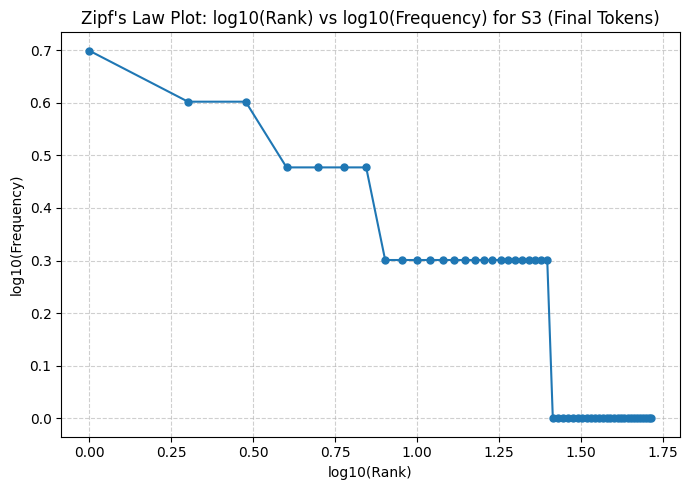

In [12]:
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nltk.stem import PorterStemmer
from nltk.util import bigrams

porter = PorterStemmer()

# 1. Build S1, S2, S3, and S4 across the entire dataset
S1 = []  # All tokens (lowercase, including punctuation and stopwords)
S2 = []  # Tokens without punctuation
S3 = []  # Final tokens (no punctuation, no stopwords)

for text in df["Ticket_Text"]:
    res = process_ticket(text)
    S1.extend(res["tokens"])
    S2.extend([t for t in res["tokens"] if not is_punct(t)])
    S3.extend(res["final"])

S4 = [porter.stem(t) for t in S3]  # S3 after Porter stemming

# 2. Compute Total Tokens, Unique Tokens, and Type-Token Ratio (TTR)
corpus_sets = {
    "S1 (All tokens)": S1,
    "S2 (No punctuation)": S2,
    "S3 (Final tokens)": S3,
    "S4 (S3 + Porter)": S4,
}

stats_rows = []
for name, tok_list in corpus_sets.items():
    total = len(tok_list)
    unique = len(set(tok_list))
    ttr = round(unique / total, 4) if total > 0 else 0.0
    stats_rows.append({
        "Stage": name,
        "Total_Tokens": total,
        "Unique_Tokens": unique,
        "TTR (Unique/Total)": ttr
    })

stats_df = pd.DataFrame(stats_rows)
print("=== Q5: Corpus Statistics (S1 - S4) ===")
print(stats_df.to_string(index=False))

# 3. Top 10 words of S1 and S3
print("\n=== Top 10 Words in S1 (All Tokens) ===")
for rank, (word, freq) in enumerate(Counter(S1).most_common(10), 1):
    print(f"{rank:2d}. {word:<15} : {freq}")

print("\n=== Top 10 Words in S3 (Final Tokens) ===")
for rank, (word, freq) in enumerate(Counter(S3).most_common(10), 1):
    print(f"{rank:2d}. {word:<15} : {freq}")

# 4. Top 5 bigrams of S1 and S3
# Computed per ticket so artificial bigrams aren't formed across ticket boundaries
s1_bigrams = []
s3_bigrams = []
for text in df["Ticket_Text"]:
    res = process_ticket(text)
    s1_bigrams.extend(list(bigrams(res["tokens"])))
    s3_bigrams.extend(list(bigrams(res["final"])))

print("\n=== Top 5 Bigrams in S1 ===")
for rank, (bg, freq) in enumerate(Counter(s1_bigrams).most_common(5), 1):
    print(f"{rank}. {bg} : {freq}")

print("\n=== Top 5 Bigrams in S3 ===")
for rank, (bg, freq) in enumerate(Counter(s3_bigrams).most_common(5), 1):
    print(f"{rank}. {bg} : {freq}")

# 5. Plot log(rank) vs log(frequency) for S3 (Zipf's Law check)
s3_counts = sorted(Counter(S3).values(), reverse=True)
ranks = np.arange(1, len(s3_counts) + 1)

plt.figure(figsize=(7, 5))
plt.plot(np.log10(ranks), np.log10(s3_counts), marker="o", linestyle="-", linewidth=1.5, markersize=5)
plt.title("Zipf's Law Plot: log10(Rank) vs log10(Frequency) for S3 (Final Tokens)")
plt.xlabel("log10(Rank)")
plt.ylabel("log10(Frequency)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

In [13]:
from nltk.stem import PorterStemmer, LancasterStemmer, WordNetLemmatizer
from nltk.corpus import wordnet
import nltk

porter = PorterStemmer()
lancaster = LancasterStemmer()
lemmatizer = WordNetLemmatizer()

print("=== Q6: Evidence Extracted Directly from Your Dataset ===\n")

# (a) TTR progression summary
for stage_name, tokens in [("S1 (All tokens)", S1), ("S2 (No punct)", S2), ("S3 (Final)", S3), ("S4 (Porter)", S4)]:
    ttr = len(set(tokens)) / len(tokens)
    print(f"  {stage_name:<18}: Unique={len(set(tokens)):3d}, Total={len(tokens):3d}, TTR={ttr:.4f}")

# (b) First ticket where word_tokenize and my_tokenize differ
print("\n(b) Tokenizer Comparison Example:")
for _, row in df.iterrows():
    wt = word_tokenize(row["Ticket_Text"])
    mt = my_tokenize(row["Ticket_Text"])
    if wt != mt:
        print(f"  Ticket [{row['Ticket_ID']}]: {row['Ticket_Text']}")
        print(f"  word_tokenize : {wt}")
        print(f"  my_tokenize   : {mt}")
        break

# (c) & (d) Stemming vs POS-aware Lemmatization examples from your unique final tokens
unique_s3 = list(dict.fromkeys(S3))
tagged_s3 = nltk.pos_tag(unique_s3)

def wn_pos(tag):
    if tag.startswith("J"): return wordnet.ADJ
    if tag.startswith("V"): return wordnet.VERB
    if tag.startswith("N"): return wordnet.NOUN
    if tag.startswith("R"): return wordnet.ADV
    return wordnet.NOUN

print("\n(c) & (d) Stemming vs. POS-Aware Lemmatization Examples:")
for word, tag in tagged_s3:
    p = porter.stem(word)
    l = lancaster.stem(word)
    lem = lemmatizer.lemmatize(word, pos=wn_pos(tag))
    if len({word, p, l, lem}) > 1:
        print(f"  Word: {word:<15} | POS: {tag:<4} | Porter: {p:<12} | Lancaster: {l:<12} | Lemma: {lem}")

=== Q6: Evidence Extracted Directly from Your Dataset ===

  S1 (All tokens)   : Unique= 79, Total=177, TTR=0.4463
  S2 (No punct)     : Unique= 75, Total=147, TTR=0.5102
  S3 (Final)        : Unique= 52, Total= 88, TTR=0.5909
  S4 (Porter)       : Unique= 49, Total= 88, TTR=0.5568

(b) Tokenizer Comparison Example:
  Ticket [T01]: I tried again... still no response!!!
  word_tokenize : ['I', 'tried', 'again', '...', 'still', 'no', 'response', '!', '!', '!']
  my_tokenize   : ['I', 'tried', 'again', '.', '.', '.', 'still', 'no', 'response', '!', '!', '!']

(c) & (d) Stemming vs. POS-Aware Lemmatization Examples:
  Word: tried           | POS: VBN  | Porter: tri          | Lancaster: tri          | Lemma: try
  Word: still           | POS: RB   | Porter: still        | Lancaster: stil         | Lemma: still
  Word: response        | POS: NN   | Porter: respons      | Lancaster: respons      | Lemma: response
  Word: keeps           | POS: NNS  | Porter: keep         | Lancaster: keep   